In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("ShopSmart - Data Exploration")

ShopSmart - Data Exploration


In [6]:
DATA_DIR = Path("../data/raw")

ratings = pd.read_csv(
    DATA_DIR / "Electronics.csv.gz",
    compression="gzip",
    nrows=10000
)

print("Dimensions :", ratings.shape)

display(ratings.head())

Dimensions : (10000, 4)


,user_id,parent_asin,rating,timestamp
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B0047T79VS,3.0,1344406083000
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B01HHURN3W,3.0,1408995743000
2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B00L0YLRUW,1.0,1439226089000
3,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B017T99JPG,5.0,1456772365000
4,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B01LW71IBJ,5.0,1456772571000


In [7]:
ratings.info()
ratings.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   user_id      10000 non-null  str    
 1   parent_asin  10000 non-null  str    
 2   rating       10000 non-null  float64
 3   timestamp    10000 non-null  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


user_id        0
parent_asin    0
rating         0
timestamp      0
dtype: int64

## 2. Exploratory Data Analysis (EDA)

We analyze the structure, quality, and statistical characteristics
of the Amazon Electronics ratings dataset.

In [8]:
print("Dataset information:")
ratings.info()

print("\nMissing values:")
display(ratings.isnull().sum())

print("\nDescriptive statistics:")
display(ratings.describe())

print("\nUnique users:", ratings["user_id"].nunique())
print("Unique products:", ratings["parent_asin"].nunique())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   user_id      10000 non-null  str    
 1   parent_asin  10000 non-null  str    
 2   rating       10000 non-null  float64
 3   timestamp    10000 non-null  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB

Missing values:


user_id        0
parent_asin    0
rating         0
timestamp      0
dtype: int64


Descriptive statistics:


,rating,timestamp
count,10000.000000,1.000000e+04
mean,4.333400,1.531307e+12
std,1.160336,9.944329e+10
min,1.000000,1.034451e+12
25%,4.000000,1.463915e+12
50%,5.000000,1.550391e+12
75%,5.000000,1.610551e+12
max,5.000000,1.678973e+12



Unique users: 641
Unique products: 8337


### Ratings Distribution

We visualize the distribution of product ratings to understand
user satisfaction and potential rating biases.

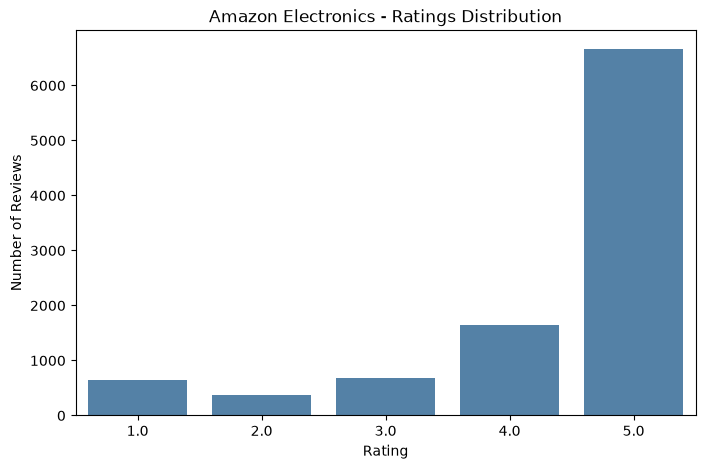

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating",
    color="steelblue"
)

plt.title("Amazon Electronics - Ratings Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

### User and Product Interaction Analysis

We analyze user activity, product popularity, and the sparsity
of the user-item interaction matrix.

In [10]:
# Number of ratings per user
user_activity = ratings.groupby("user_id").size()

# Number of ratings per product
product_popularity = ratings.groupby("parent_asin").size()

print("Ratings per user:")
display(user_activity.describe())

print("\nRatings per product:")
display(product_popularity.describe())

# Sparsity calculation
n_users = ratings["user_id"].nunique()
n_products = ratings["parent_asin"].nunique()

n_interactions = ratings[
    ["user_id", "parent_asin"]
].drop_duplicates().shape[0]

density = n_interactions / (n_users * n_products)
sparsity = 1 - density

print(f"\nMatrix density: {density:.4%}")
print(f"Matrix sparsity: {sparsity:.4%}")

Ratings per user:


count    641.000000
mean      15.600624
std       23.792717
min        3.000000
25%        6.000000
50%        9.000000
75%       15.000000
max      222.000000
dtype: float64


Ratings per product:


count    8337.000000
mean        1.199472
std         0.938185
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        34.000000
dtype: float64


Matrix density: 0.1871%
Matrix sparsity: 99.8129%


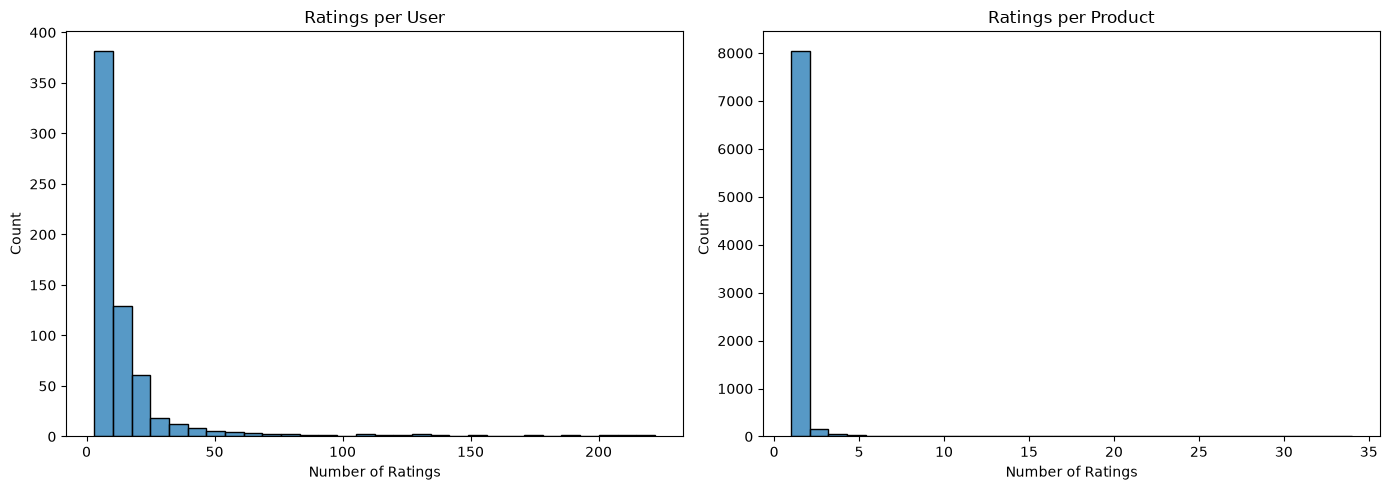

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    user_activity,
    bins=30,
    ax=axes[0]
)

axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of Ratings")

sns.histplot(
    product_popularity,
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Ratings per Product")
axes[1].set_xlabel("Number of Ratings")

plt.tight_layout()
plt.show()

## 3. Product Metadata Exploration

We explore the Amazon Electronics product catalog to identify
the features required for content-based recommendations.

In [12]:
import json
import gzip

metadata_path = DATA_DIR / "meta_Electronics.jsonl.gz"

products_sample = []

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= 1000:
            break
        products_sample.append(json.loads(line))

products = pd.DataFrame(products_sample)

print("Dimensions:", products.shape)
print("\nAvailable columns:")
print(products.columns.tolist())

display(products.head(3))

Dimensions: (1000, 16)

Available columns:
['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,All Electronics,FS-1051 FATSHARK TELEPORTER V3 HEADSET,3.5,6,[],[Teleporter V3 The “Teleporter V3” kit sets a ...,NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Fat Shark,"[Electronics, Television & Video, Video Glasses]","{'Date First Available': 'August 2, 2014', 'Ma...",B00MCW7G9M,None,NaN,NaN
1,All Electronics,Ce-H22B12-S1 4Kx2K Hdmi 4Port,5.0,1,"[UPC: 662774021904, Weight: 0.600 lbs]",[HDMI In - HDMI Out],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],SIIG,"[Electronics, Television & Video, Accessories,...",{'Product Dimensions': '0.83 x 4.17 x 2.05 inc...,B00YT6XQSE,None,NaN,NaN
2,Computers,Digi-Tatoo Decal Skin Compatible With MacBook ...,4.5,246,[WARNING: Please IDENTIFY MODEL NUMBER on the ...,[],19.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'AL 2Sides Video', 'url': 'https://...",Digi-Tatoo,"[Electronics, Computers & Accessories, Laptop ...","{'Brand': 'Digi-Tatoo', 'Color': 'Fresh Marble...",B07SM135LS,None,NaN,NaN


In [13]:
important_columns = [
    "parent_asin",
    "title",
    "main_category",
    "price",
    "description",
    "features"
]

display(products[important_columns].head(10))

print("\nMissing values (%):")
display(
    (
        products[important_columns]
        .isnull()
        .mean()
        .mul(100)
        .round(2)
    )
)

,parent_asin,title,main_category,price,description,features
0,B00MCW7G9M,FS-1051 FATSHARK TELEPORTER V3 HEADSET,All Electronics,NaN,[Teleporter V3 The “Teleporter V3” kit sets a ...,[]
1,B00YT6XQSE,Ce-H22B12-S1 4Kx2K Hdmi 4Port,All Electronics,NaN,[HDMI In - HDMI Out],"[UPC: 662774021904, Weight: 0.600 lbs]"
2,B07SM135LS,Digi-Tatoo Decal Skin Compatible With MacBook ...,Computers,19.99,[],[WARNING: Please IDENTIFY MODEL NUMBER on the ...
3,B089CNGZCW,NotoCity Compatible with Vivoactive 4 band 22m...,AMAZON FASHION,9.99,[],[☛NotoCity 22mm band is designed for Vivoactiv...
4,B004E2Z88O,Motorola Droid X Essentials Combo Pack,Cell Phones & Accessories,14.99,[all Genuine High Quality Motorola Made Access...,"[New Droid X Essentials Combo Pack, Exclusive ..."
5,B00TX536EK,Raymarine Wi-Fish DownVision Blackbox Sonar wi...,Sports & Outdoors,NaN,[Transform your smartphone into a powerful CHI...,[Black box Wi-Fi CHIRP DownVision sonar module...
6,B07BJ7ZZL7,"QGHXO Band for Garmin Vivofit 4, Soft Silicone...",Cell Phones & Accessories,14.89,"[Compatibility, Custom designed for your preci...",[Personalized Your Garmin Vivofit 4 Activity T...
7,B005G99O2U,Protech iPhone 4 microscope 60X Lens with illu...,Industrial & Scientific,NaN,[This accessory will convert your iPhone 4 int...,[iPhone 4 Microscope with White 2-LED and Dete...
8,B01MCZP7RF,MOSISO Plastic Hard Shell Case & Keyboard Cove...,Computers,NaN,[],[]
9,B00R6R82HS,"Fishfinder, Depth Finder Poly Sun Cover for 3""...",NaN,10.99,[Affordable and convenient way to cover your s...,"[Made of poly material, Available in black, Dr..."



Missing values (%):


parent_asin       0.0
title             0.0
main_category     1.1
price            56.8
description       0.0
features          0.0
dtype: float64

### Metadata Quality Analysis

We evaluate the availability of textual product features
to determine which attributes can be used for content-based filtering.

In [14]:
# Check textual information availability
metadata_quality = pd.DataFrame({
    "Title": products["title"].fillna("").str.strip().ne(""),
    "Description": products["description"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    ),
    "Features": products["features"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    ),
    "Categories": products["categories"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    ),
    "Price": products["price"].notna()
})

availability = (
    metadata_quality.mean() * 100
).round(2)

display(availability.to_frame("Availability (%)"))

,Availability (%)
Title,100.0
Description,55.6
Features,77.1
Categories,92.9
Price,43.2


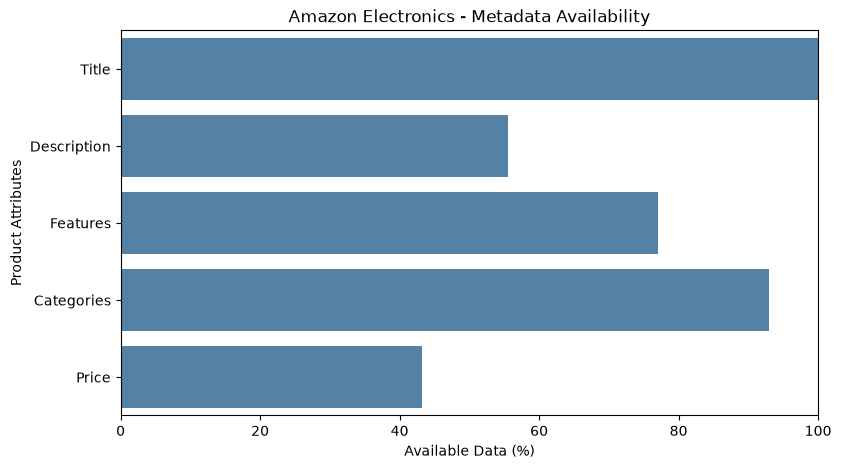

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=availability.values,
    y=availability.index,
    color="steelblue"
)

plt.title("Amazon Electronics - Metadata Availability")
plt.xlabel("Available Data (%)")
plt.ylabel("Product Attributes")
plt.xlim(0, 100)

plt.show()

## 4. Dataset Selection and Preparation

We process the complete Amazon Electronics ratings dataset
in chunks to identify frequently rated products and active users.

Our goal is to construct a manageable and sufficiently connected
user-item dataset for recommendation algorithms.

In [16]:
from collections import Counter

ratings_path = DATA_DIR / "Electronics.csv.gz"

product_counts = Counter()
total_ratings = 0

chunk_size = 250_000

for chunk in pd.read_csv(
    ratings_path,
    compression="gzip",
    usecols=["user_id", "parent_asin", "rating"],
    chunksize=chunk_size
):
    product_counts.update(
        chunk["parent_asin"].value_counts().to_dict()
    )

    total_ratings += len(chunk)

print(f"Total ratings processed: {total_ratings:,}")
print(f"Unique products: {len(product_counts):,}")

top_products = pd.DataFrame(
    product_counts.most_common(10),
    columns=["parent_asin", "rating_count"]
)

display(top_products)

Total ratings processed: 15,473,536
Unique products: 368,228


,parent_asin,rating_count
0,B075X8471B,44948
1,B01K8B8YA8,39313
2,B07GZFM1ZM,36533
3,B010BWYDYA,26228
4,B07S764D9V,21534
5,B07H65KP63,21424
6,B0791TX5P5,19888
7,B011BRUOMO,17536
8,B07KTYJ769,16594
9,B0BW4PFM58,15384


### Active User Selection

We identify users with the highest number of interactions
among the 2,000 most frequently rated products.

This helps us build a more connected user-item dataset.

In [17]:
# Select the 2,000 most frequently rated products
TOP_N_PRODUCTS = 2000

selected_products = set(
    asin for asin, count
    in product_counts.most_common(TOP_N_PRODUCTS)
)

# Count user activity within selected products
user_counts = Counter()
filtered_ratings_count = 0

for chunk in pd.read_csv(
    ratings_path,
    compression="gzip",
    usecols=["user_id", "parent_asin", "rating"],
    chunksize=250_000
):
    filtered_chunk = chunk[
        chunk["parent_asin"].isin(selected_products)
    ]

    user_counts.update(
        filtered_chunk["user_id"].value_counts().to_dict()
    )

    filtered_ratings_count += len(filtered_chunk)

print("Selected products:", len(selected_products))
print("Ratings for selected products:", filtered_ratings_count)
print("Unique users:", len(user_counts))

# User activity statistics
user_activity_full = pd.Series(
    user_counts, name="rating_count"
)

display(user_activity_full.describe())

# Most active users
display(user_activity_full.nlargest(10))

Selected products: 2000
Ratings for selected products: 3761470
Unique users: 1360474


count    1.360474e+06
mean     2.764823e+00
std      2.379045e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      9.700000e+01
Name: rating_count, dtype: float64

AGRHKDNSRJ3CT5ST75KGSCD4WA5A    97
AGYAEVOMGHEDXJBRT2URFA53UBGA    87
AGAASUFJNV3AH2OMGQK5L2YGWXAQ    81
AHMNA5UK3V66O2V3DZSBJA4FYMOA    74
AGANTN6HRGMCMQP2KT7TTNZDUY3Q    72
AHYI3O22APDQVJ3CXEJRHUYYR2BA    70
AHL3TEVTN5EZI7TWZRLAO4EULXKA    70
AGQ5BLIJHPKHQORUJ7XJNROM7WGA    69
AHEHAYQOGUBWQSEQEJEZYQOBR2QQ    68
AGKKGFBWDJFYN3UUSJ62XCI42QVQ    67
Name: rating_count, dtype: int64

### User Activity Threshold Analysis

We compare different minimum interaction thresholds to identify
sufficiently active users for collaborative filtering.

In [18]:
# Compare different minimum activity thresholds

thresholds = [5, 10, 15, 20, 30]

threshold_results = []

for threshold in thresholds:

    eligible_users = user_activity_full[
        user_activity_full >= threshold
    ]

    threshold_results.append({
        "Min Ratings": threshold,
        "Users": len(eligible_users),
        "Interactions": int(eligible_users.sum()),
        "Avg Ratings/User": round(
            eligible_users.mean(), 2
        ) if len(eligible_users) > 0 else 0
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Min Ratings,Users,Interactions,Avg Ratings/User
0,5,184327,1325680,7.19
1,10,26682,367096,13.76
2,15,7368,147572,20.03
3,20,2737,71085,25.97
4,30,548,20407,37.24


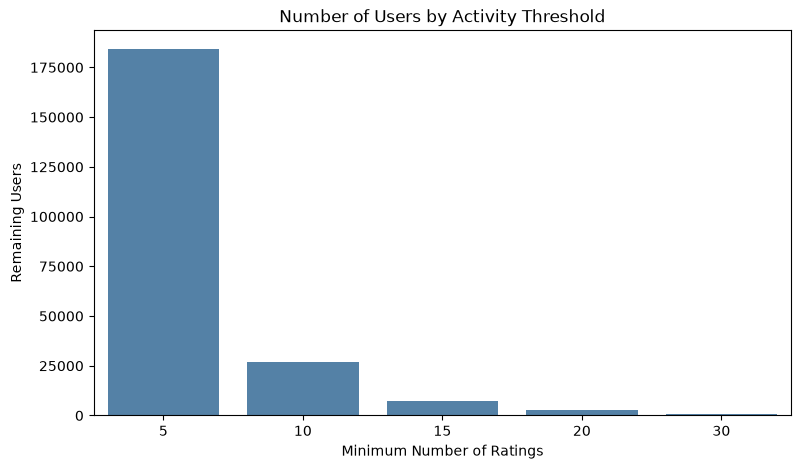

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=threshold_df,
    x="Min Ratings",
    y="Users",
    color="steelblue"
)

plt.title("Number of Users by Activity Threshold")
plt.xlabel("Minimum Number of Ratings")
plt.ylabel("Remaining Users")

plt.show()

### Final User-Item Dataset Construction

We select users with at least 15 ratings among the 2,000
most popular products and extract their interactions.

We remove duplicate user-product pairs and save the
resulting dataset for recommendation modeling.

In [21]:
MIN_USER_RATINGS = 15

# Select eligible users
selected_users = set(
    user_activity_full[
        user_activity_full >= MIN_USER_RATINGS
    ].index
)

print("Selected users:", len(selected_users))
print("Selected products:", len(selected_products))

Selected users: 7368
Selected products: 2000


In [22]:
filtered_chunks = []

for chunk in pd.read_csv(
    ratings_path,
    compression="gzip",
    usecols=["user_id", "parent_asin", "rating", "timestamp"],
    chunksize=250_000
):

    filtered = chunk[
        chunk["user_id"].isin(selected_users)
        & chunk["parent_asin"].isin(selected_products)
    ]

    if not filtered.empty:
        filtered_chunks.append(filtered.copy())

# Combine selected interactions
ratings_final = pd.concat(
    filtered_chunks,
    ignore_index=True
)

# Keep the latest rating in case of duplicates
ratings_final = (
    ratings_final
    .sort_values("timestamp")
    .drop_duplicates(
        subset=["user_id", "parent_asin"],
        keep="last"
    )
    .reset_index(drop=True)
)

print("Final dataset shape:", ratings_final.shape)
print("Unique users:", ratings_final["user_id"].nunique())
print("Unique products:", ratings_final["parent_asin"].nunique())

display(ratings_final.head())

Final dataset shape: (147572, 4)
Unique users: 7368
Unique products: 2000


,user_id,parent_asin,rating,timestamp
0,AEQI35XCPNA3Y3KLF777F7IJQFXQ,B00CTUXKWY,5.0,1031856734000
1,AFZ4EK2LJ655XQKTEUELCARO6RYA,B00002EQCW,4.0,1043292495000
2,AHHWI6X47RXVMZOZCKRZCGZG36CQ,B0001FTVEK,5.0,1115447929000
3,AE3FLMG6UWQPRX3VVZVNU44VZH4Q,B00006JN3G,5.0,1126493401000
4,AFBTEUJ64WBMX6OGWXMX3LYMTXOA,B00YCBLR5U,4.0,1128893792000


In [23]:
n_users = ratings_final["user_id"].nunique()
n_items = ratings_final["parent_asin"].nunique()
n_ratings = len(ratings_final)

density = n_ratings / (n_users * n_items)

print(f"Users: {n_users:,}")
print(f"Products: {n_items:,}")
print(f"Interactions: {n_ratings:,}")

print(f"Density: {density:.4%}")
print(f"Sparsity: {1 - density:.4%}")

print("\nRatings per user:")
display(
    ratings_final.groupby("user_id")
    .size()
    .describe()
)

print("\nRatings per product:")
display(
    ratings_final.groupby("parent_asin")
    .size()
    .describe()
)

Users: 7,368
Products: 2,000
Interactions: 147,572
Density: 1.0014%
Sparsity: 98.9986%

Ratings per user:


count    7368.000000
mean       20.028773
std         6.432406
min        15.000000
25%        16.000000
50%        18.000000
75%        22.000000
max        97.000000
dtype: float64


Ratings per product:


count    2000.00000
mean       73.78600
std        83.89044
min         5.00000
25%        30.00000
50%        50.00000
75%        84.00000
max      1129.00000
dtype: float64

In [24]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

ratings_final.to_csv(
    PROCESSED_DIR / "ratings_shopsmart.csv",
    index=False
)

print("ShopSmart ratings dataset saved!")

ShopSmart ratings dataset saved!


## 5. Product Metadata Extraction

We extract metadata only for the 2,000 products selected
in our recommendation dataset.

The extracted attributes will be used to build
content-based recommendation models.

In [25]:
# Get the exact products present in our final dataset
target_asins = set(ratings_final["parent_asin"].unique())

selected_metadata = {}
total_scanned = 0

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    for line in f:
        total_scanned += 1
        product = json.loads(line)
        asin = product.get("parent_asin")

        if asin in target_asins:
            selected_metadata[asin] = product

        if len(selected_metadata) == len(target_asins):
            break

print(f"Metadata records scanned: {total_scanned:,}")
print(f"Products requested: {len(target_asins):,}")
print(f"Products found: {len(selected_metadata):,}")
print(f"Products missing: {len(target_asins - selected_metadata.keys()):,}")

Metadata records scanned: 1,380,133
Products requested: 2,000
Products found: 2,000
Products missing: 0


In [26]:
products_final = pd.DataFrame(
    selected_metadata.values()
)

columns_to_keep = [
    "parent_asin",
    "title",
    "main_category",
    "categories",
    "features",
    "description",
    "price",
    "store"
]

products_final = products_final[columns_to_keep].copy()

print("Products dataset shape:", products_final.shape)

display(products_final.head())

Products dataset shape: (2000, 8)


,parent_asin,title,main_category,categories,features,description,price,store
0,B07RWDZ3HG,SilverStone Technology SST-FF121 120mm Ultra F...,All Electronics,"[Electronics, Computers & Accessories, Compute...","[Honeycomb grill increases airflow focus, Inte...",[Finding a quiet and efficient cooling fan is ...,6.47,SilverStone Technology
1,B09SJ9192T,"SAMSUNG 23.5” CF396 Curved Computer Monitor, A...",Computers,"[Electronics, Computers & Accessories, Monitors]",[IMMERSIVE VIEWING EXPERIENCE: The 1800R curva...,[Enjoy a truly immersive viewing experience wi...,158.00,SAMSUNG
2,B07FTSFGXH,"Cat6 Ethernet Cable, 12 Feet (2 Pack) LAN, utp...",Industrial & Scientific,"[Electronics, Computers & Accessories, Compute...",[QUALITY CONTROL - Each Cat 6 internet cable 5...,[],11.99,Ultra Clarity Cables
3,B00RVFCFI2,ExpertPower XP-669 7.5-Inch Dual Band SMA-F An...,Cell Phones & Accessories,"[Electronics, Television & Video, Accessories,...",[A Reputation that Proceeds – The XP-669C ante...,"[Meet the Antenna You Have Been Looking For, A...",12.25,ExpertPower
4,B0C49KQRX4,Tzowla Travel Laptop Backpack Water Resistant ...,Computers,"[Electronics, Computers & Accessories, Laptop ...",[[Large Capacity and Organized] Tzowla backpac...,[],25.49,Tzowla


In [27]:
ratings_asins = set(ratings_final["parent_asin"])
metadata_asins = set(products_final["parent_asin"])

matched = ratings_asins & metadata_asins
missing = ratings_asins - metadata_asins

print("Products in ratings:", len(ratings_asins))
print("Products with metadata:", len(matched))
print("Products without metadata:", len(missing))

print(
    f"Metadata coverage: "
    f"{len(matched) / len(ratings_asins):.2%}"
)

print("\nMissing values:")
display(
    products_final.isnull().sum()
)

Products in ratings: 2000
Products with metadata: 2000
Products without metadata: 0
Metadata coverage: 100.00%

Missing values:


parent_asin        0
title              0
main_category     18
categories         0
features           0
description        0
price            507
store              0
dtype: int64

In [28]:
products_final.to_json(
    PROCESSED_DIR / "products_shopsmart.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

print("ShopSmart product metadata saved!")

ShopSmart product metadata saved!
